# SHAP sample-size convergence (archived)

Frozen record of the investigation behind ADR-0004's sample-size decision: how many rows does `shap.explainers.Permutation` need to explain before the per-feature estimate is trustworthy? Computed against run `b665bce86cd34ad49d44116ab80dcbf1` (the first successful `hgb_train_eval` run). **Not meant to be re-run** -- the sweep up to n=800 is expensive (confirmed: ~20 minutes using 7-8 cores). The conclusion (n=200 is sufficient, ~7.7% worst-case relative SE) is logged in ADR-0004 and doesn't depend on which specific run produced it; outputs here are preserved as evidence, not for rerunning.

In [1]:
RUN_ID = "b665bce86cd34ad49d44116ab80dcbf1"  # hgb_train_eval (first successful run)

In [2]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import shap
from dotenv import load_dotenv
from sklearn.inspection import permutation_importance


def find_root(start: Path) -> Path:
    p = start.resolve()
    while not (p / "pyproject.toml").exists():
        p = p.parent
    return p


ROOT = find_root(Path.cwd())
sys.path.insert(0, str(ROOT / "src"))
from taxi_mlops.config import load_params  # noqa: E402
from taxi_mlops.features import build_feature_table, feature_columns, split_by_period  # noqa: E402

load_dotenv(ROOT / ".env")
mlflow.set_tracking_uri(os.getenv("MLFLOW_TRACKING_URI", "http://127.0.0.1:5000"))

params = load_params(ROOT / "params.yaml")
cols = feature_columns(params)
cols

['lag_1',
 'lag_2',
 'lag_3',
 'lag_24',
 'lag_168',
 'roll_3',
 'roll_24',
 'roll_168',
 'hour_of_day',
 'day_of_week',
 'is_weekend',
 'zone_id']

## Load the logged model and the test split (identical to training)

In [3]:
model = mlflow.sklearn.load_model(f"runs:/{RUN_ID}/model")

zone_ids = [
    z["zone_id"]
    for z in json.loads((ROOT / "config" / "selected_zones.json").read_text())
]
zone_hour = pd.read_parquet(ROOT / "data" / "processed" / "zone_hour_counts.parquet")
zone_hour = zone_hour[zone_hour.zone_id.isin(zone_ids)]
feature_table = build_feature_table(zone_hour, params)
train = split_by_period(feature_table, params, "train")
test = split_by_period(feature_table, params, "test")
X_test, y_test = test[cols], test["target"]
X_test.shape

(6240, 12)

## SHAP values already logged on this run

Download the artifact rather than recomputing it -- same values the training run produced.

In [4]:
local_dir = mlflow.artifacts.download_artifacts(run_id=RUN_ID, artifact_path="shap")
npz = np.load(Path(local_dir) / "shap_values.npz", allow_pickle=True)
shap_values = npz["shap_values"]
feature_names = list(npz["feature_names"])
mean_abs_shap = pd.Series(
    np.abs(shap_values).mean(axis=0), index=feature_names, name="mean_abs_shap"
)
mean_abs_shap.sort_values(ascending=False)

lag_2          0.419168
roll_3         0.279696
lag_168        0.190133
day_of_week    0.137052
hour_of_day    0.095148
lag_24         0.040816
lag_1          0.021879
is_weekend     0.017675
lag_3          0.009861
roll_168       0.005618
roll_24        0.004679
zone_id        0.000000
Name: mean_abs_shap, dtype: float64

## Permutation importance

Independent of SHAP's internals entirely -- shuffle one column at a time, remeasure MAE, repeat. Scored on the same test split, same model, so this is a direct cross-check, not a different experiment.

In [5]:
result = permutation_importance(
    model,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=params["random_seed"],
)
perm_importance = pd.Series(
    result.importances_mean, index=cols, name="perm_importance_mae_increase"
)
perm_std = pd.Series(result.importances_std, index=cols, name="perm_importance_std")
perm_importance.sort_values(ascending=False)

lag_1          82.582320
lag_24         30.929662
lag_168        28.383268
hour_of_day     9.336173
lag_3           5.105067
zone_id         4.848960
day_of_week     4.184514
roll_168        2.030271
lag_2           0.947216
roll_24         0.945872
roll_3          0.614121
is_weekend      0.000000
Name: perm_importance_mae_increase, dtype: float64

## Side-by-side comparison

Both methods, same features, same model, same data. If they agree on `zone_id` contributing ~nothing, that's real; if they disagree, the SHAP computation itself needs a closer look before trusting it for anything else.

In [6]:
comparison = pd.DataFrame(
    {
        "mean_abs_shap": mean_abs_shap,
        "perm_importance_mae_increase": perm_importance,
        "perm_importance_std": perm_std,
    }
).sort_values("perm_importance_mae_increase", ascending=False)
comparison

,mean_abs_shap,perm_importance_mae_increase,perm_importance_std
lag_1,0.021879,82.582320,1.045604
lag_24,0.040816,30.929662,0.465078
lag_168,0.190133,28.383268,0.495963
hour_of_day,0.095148,9.336173,0.127737
lag_3,0.009861,5.105067,0.186426
zone_id,0.000000,4.848960,0.210371
day_of_week,0.137052,4.184514,0.190837
roll_168,0.005618,2.030271,0.179091
lag_2,0.419168,0.947216,0.059995
roll_24,0.004679,0.945872,0.073802


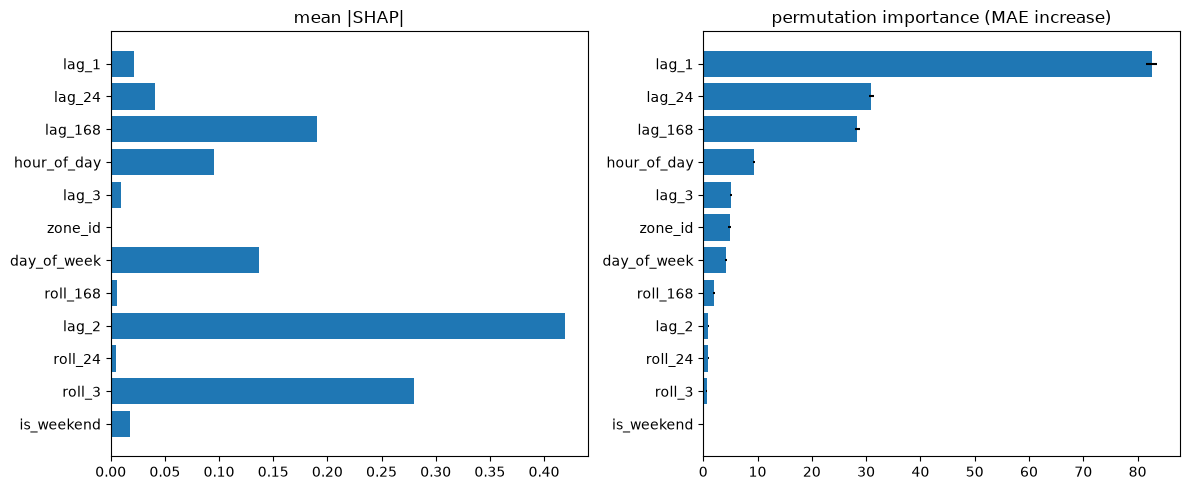

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
order = comparison.index
axes[0].barh(order, comparison.loc[order, "mean_abs_shap"])
axes[0].set_title("mean |SHAP|")
axes[0].invert_yaxis()
axes[1].barh(
    order,
    comparison.loc[order, "perm_importance_mae_increase"],
    xerr=comparison.loc[order, "perm_importance_std"],
)
axes[1].set_title("permutation importance (MAE increase)")
axes[1].invert_yaxis()
plt.tight_layout()
plt.show()

## Root cause, step 1: perturbation assumption

`TreeExplainer`'s default (`tree_path_dependent`) estimates each feature's contribution using the training data's correlation structure along the tree's actual split paths. Permutation importance instead breaks one feature's relationship with the target directly by shuffling it while leaving everything else untouched. Under correlated features these answer genuinely different questions -- so before assuming a bug, try TreeExplainer's other mode (`interventional`), which uses an explicit background sample instead of path-dependent conditioning, and is closer in spirit to what permutation importance does.

In [8]:
background = train[cols].sample(n=200, random_state=params["random_seed"])
explainer_interventional = shap.TreeExplainer(
    model, data=background, feature_perturbation="interventional"
)
shap_values_interventional = explainer_interventional.shap_values(
    X_test.sample(n=500, random_state=params["random_seed"])
)
mean_abs_shap_interventional = pd.Series(
    np.abs(shap_values_interventional).mean(axis=0),
    index=cols,
    name="mean_abs_shap_interventional",
).sort_values(ascending=False)
mean_abs_shap_interventional

Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


lag_2          0.510284
lag_168        0.192524
roll_3         0.169654
day_of_week    0.084960
lag_24         0.056946
lag_3          0.012250
roll_168       0.007412
roll_24        0.004636
is_weekend     0.004110
lag_1          0.000000
hour_of_day    0.000000
zone_id        0.000000
Name: mean_abs_shap_interventional, dtype: float64

## Root cause, step 2: fully model-agnostic explainer

If `interventional` still disagrees with permutation importance, the disagreement isn't about path-dependence vs. interventional perturbation -- it points at `TreeExplainer`'s handling of this model's native categorical splits specifically. Cross-check with a model-agnostic explainer that only calls `model.predict` and never inspects the tree structure at all, so it cannot be affected by that.

In [9]:
sample_test = X_test.sample(n=100, random_state=params["random_seed"])
masker = shap.maskers.Independent(background, max_samples=200)
agnostic_explainer = shap.explainers.Permutation(model.predict, masker)
agnostic_result = agnostic_explainer(sample_test)
mean_abs_shap_agnostic = pd.Series(
    np.abs(agnostic_result.values).mean(axis=0),
    index=cols,
    name="mean_abs_shap_agnostic",
).sort_values(ascending=False)
mean_abs_shap_agnostic

PermutationExplainer explainer:  14%|█▍        | 14/100 [00:00<?, ?it/s]

PermutationExplainer explainer:  16%|█▌        | 16/100 [00:11<00:48,  1.72it/s]

PermutationExplainer explainer:  17%|█▋        | 17/100 [00:11<00:46,  1.77it/s]

PermutationExplainer explainer:  18%|█▊        | 18/100 [00:12<00:55,  1.47it/s]

PermutationExplainer explainer:  19%|█▉        | 19/100 [00:13<00:49,  1.64it/s]

PermutationExplainer explainer:  20%|██        | 20/100 [00:14<00:54,  1.45it/s]

... (79 outputs left out)

PermutationExplainer explainer: 100%|██████████| 100/100 [01:12<00:00,  1.47it/s]

PermutationExplainer explainer: 101it [01:13,  1.31it/s]                         

PermutationExplainer explainer: 101it [01:13,  1.19it/s]

lag_1          87.364213
lag_24         41.794810
lag_168        39.698328
hour_of_day    14.576292
lag_3          12.459069
zone_id         7.143432
roll_168        5.881592
day_of_week     5.705065
roll_24         3.051418
lag_2           2.336959
roll_3          1.772014
is_weekend      0.000000
Name: mean_abs_shap_agnostic, dtype: float64

## Is the explain-sample size actually enough?

`permutation_importance` above used the full 6,240-row test set with 10 repeats -- far more statistically robust than a 100-200 row SHAP subsample. Rather than guess a bigger number, measure it: compute mean |SHAP| and its standard error (std / sqrt(n)) at increasing sample sizes, using the same background each time, and look at relative standard error (SE / mean) per feature -- the usual heuristic is to want this comfortably below ~15-20% before trusting a ranking, especially for features close in magnitude.

In [10]:
sizes = [50, 100, 200, 400, 800]
se_rows = []
for n in sizes:
    s = X_test.sample(n=min(n, len(X_test)), random_state=params["random_seed"])
    vals = agnostic_explainer(s).values
    mean_abs = np.abs(vals).mean(axis=0)
    se = np.abs(vals).std(axis=0, ddof=1) / np.sqrt(len(s))
    relative_se = se / np.where(mean_abs > 0, mean_abs, np.nan)
    for col, m, s_, rse in zip(cols, mean_abs, se, relative_se):
        se_rows.append(
            {"n": n, "feature": col, "mean_abs_shap": m, "se": s_, "relative_se": rse}
        )

se_df = pd.DataFrame(se_rows)
pivot_relative_se = se_df.pivot(index="feature", columns="n", values="relative_se")
pivot_relative_se = pivot_relative_se.reindex(
    comparison.index if "comparison" in dir() else pivot_relative_se.index
)
(pivot_relative_se * 100).round(1)

PermutationExplainer explainer:  32%|███▏      | 16/50 [00:00<?, ?it/s]

PermutationExplainer explainer:  36%|███▌      | 18/50 [00:11<00:06,  4.85it/s]

PermutationExplainer explainer:  38%|███▊      | 19/50 [00:11<00:15,  2.05it/s]

PermutationExplainer explainer:  40%|████      | 20/50 [00:12<00:14,  2.10it/s]

PermutationExplainer explainer:  42%|████▏     | 21/50 [00:13<00:17,  1.69it/s]

PermutationExplainer explainer:  44%|████▍     | 22/50 [00:13<00:16,  1.73it/s]

... (1,473 outputs left out)

PermutationExplainer explainer: 100%|██████████| 800/800 [11:05<00:00,  1.03s/it]

PermutationExplainer explainer: 801it [11:06,  1.06s/it]                         

PermutationExplainer explainer: 801it [11:06,  1.18it/s]

n,50,100,200,400,800
lag_1,11.1,8.1,5.9,4.2,2.9
lag_24,9.9,7.3,5.3,3.7,2.6
lag_168,12.9,8.8,6.4,4.3,3.0
hour_of_day,10.3,7.5,4.9,3.4,2.5
lag_3,15.2,9.6,5.7,4.0,2.9
zone_id,15.8,11.2,7.2,5.0,3.5
day_of_week,11.4,8.8,7.4,5.3,3.6
roll_168,13.2,9.5,6.7,4.6,3.3
lag_2,17.0,11.1,7.7,5.2,3.8
roll_24,14.6,10.5,7.3,4.9,3.5


max relative SE across all features, by sample size:
n
50     17.0
100    11.2
200     7.7
400     5.3
800     3.8


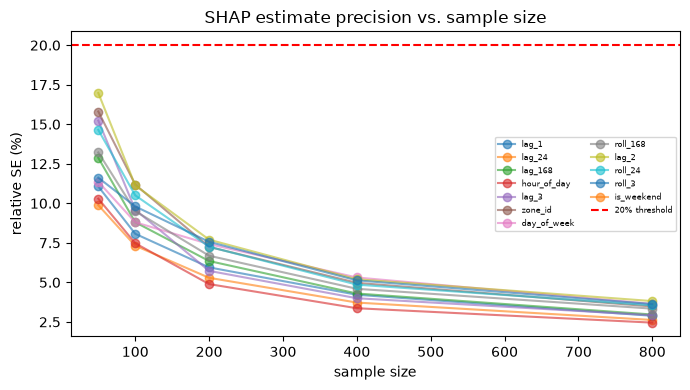

In [11]:
worst_relative_se_at_n = pivot_relative_se.max(axis=0)
print("max relative SE across all features, by sample size:")
print((worst_relative_se_at_n * 100).round(1).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
for feature in pivot_relative_se.index:
    ax.plot(
        sizes,
        pivot_relative_se.loc[feature] * 100,
        marker="o",
        label=feature,
        alpha=0.6,
    )
ax.axhline(20, color="red", linestyle="--", label="20% threshold")
ax.set_xlabel("sample size")
ax.set_ylabel("relative SE (%)")
ax.set_title("SHAP estimate precision vs. sample size")
ax.legend(fontsize=6, ncol=2)
plt.tight_layout()
plt.show()

## Full comparison: four signals side by side

In [12]:
full_comparison = pd.DataFrame(
    {
        "shap_tree_path_dependent": mean_abs_shap,
        "shap_tree_interventional": mean_abs_shap_interventional,
        "shap_model_agnostic": mean_abs_shap_agnostic,
        "perm_importance": perm_importance,
    }
).sort_values("perm_importance", ascending=False)
full_comparison

,shap_tree_path_dependent,shap_tree_interventional,shap_model_agnostic,perm_importance
lag_1,0.021879,0.000000,87.364213,82.582320
lag_24,0.040816,0.056946,41.794810,30.929662
lag_168,0.190133,0.192524,39.698328,28.383268
hour_of_day,0.095148,0.000000,14.576292,9.336173
lag_3,0.009861,0.012250,12.459069,5.105067
zone_id,0.000000,0.000000,7.143432,4.848960
day_of_week,0.137052,0.084960,5.705065,4.184514
roll_168,0.005618,0.007412,5.881592,2.030271
lag_2,0.419168,0.510284,2.336959,0.947216
roll_24,0.004679,0.004636,3.051418,0.945872


## Conclusion

Fill in after running: does `interventional` perturbation (step 1) resolve the disagreement with permutation importance? If yes, this was a perturbation-assumption mismatch, not a bug -- `tree_path_dependent` SHAP simply answers a different question under correlated features. If `interventional` still disagrees but the model-agnostic explainer (step 2) agrees with permutation importance, that implicates `TreeExplainer`'s handling of this model's native categorical splits specifically. Update ADR-0004 with whichever it turns out to be, and only then decide whether zone_id or any lag/rolling feature should actually be dropped.